# CRPNet training
Class, rotation, centre och colour. All kod finns i `neural_net/`; notebooken kör den och ritar grafer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import clear_output

from neural_net.config import CLASSES, COLOURS, SYMMETRY_DEG, NORM_MEAN, NORM_STD, IMG_SIZE
from neural_net.labels import load_crops
from neural_net.dataset import CRPDataset, make_loaders
from neural_net import train as T

EPOCHS = 60
PLOT_COLOURS = {"red": "#dc2626", "green": "#16a34a", "blue": "#2563eb"}
print("device:", T.DEVICE)

device: cpu


## Data

200 crops after removing bad ones


colour,blue,green,red
shape,,,
Circle,0,0,13
Hexagon,0,15,22
Square,0,0,32
Star,56,0,0
Triangle,0,24,38


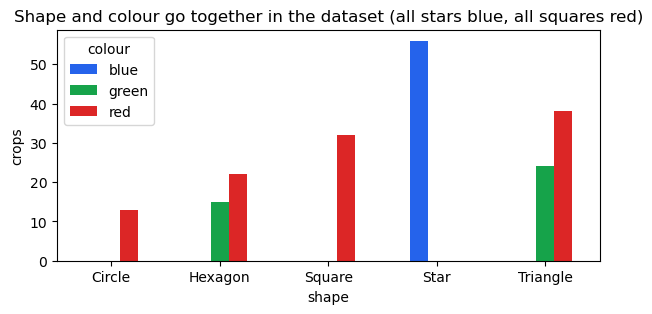

In [2]:
crops = load_crops()
print(len(crops), "crops after removing bad ones")
table = pd.crosstab(crops["shape"], crops["colour"])
display(table)
table.plot.bar(color=[PLOT_COLOURS[c] for c in table.columns], figsize=(7, 3), rot=0,
               title="Shape and colour go together in the dataset (all stars blue, all squares red)")
plt.ylabel("crops"); plt.show()

## Training-bilder
Varje bild vrids, skalas och får bytta färgkanaler. Labels följer med: centre (prick), rotation (pil) och colour (titel).

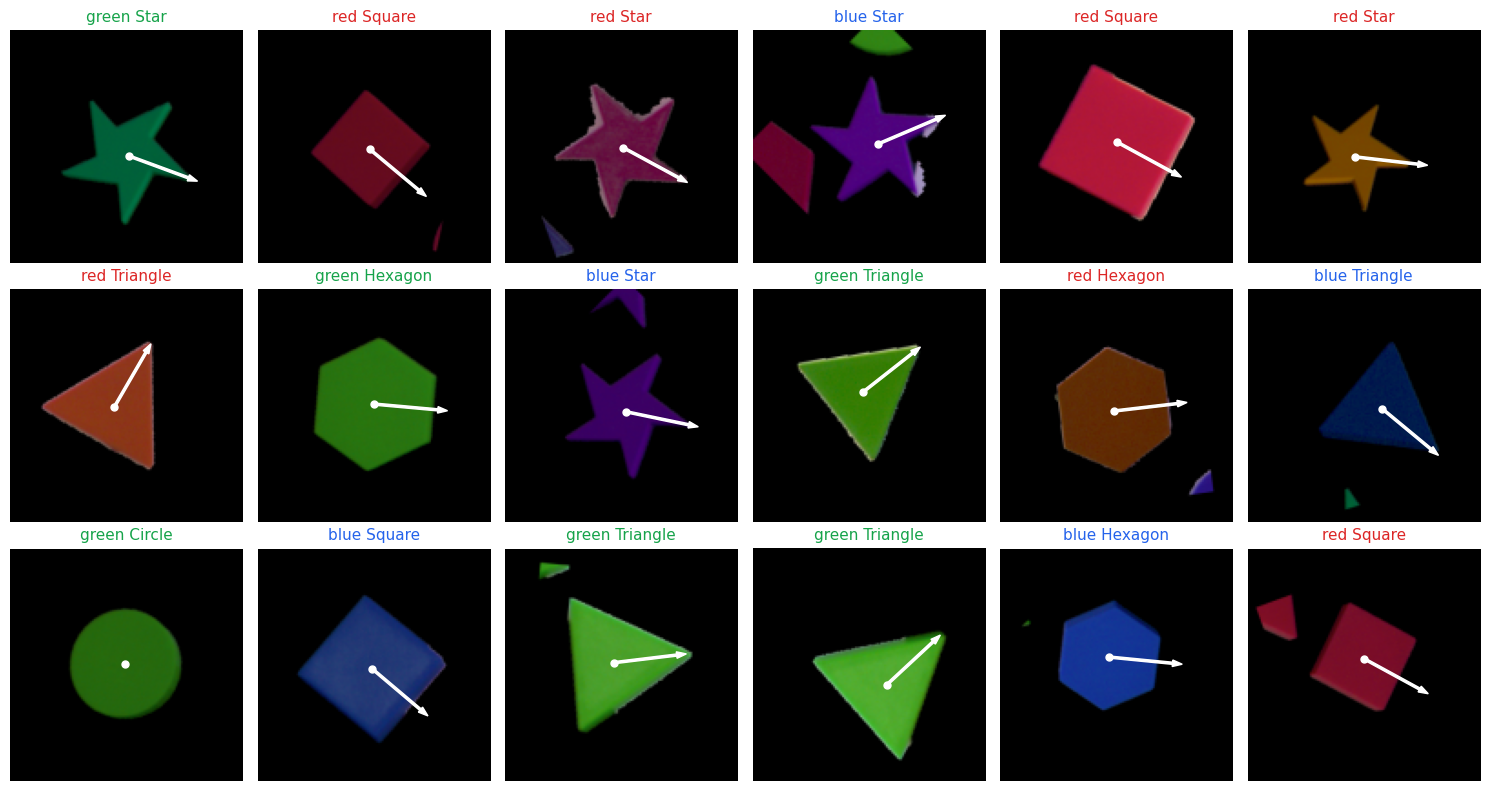

In [3]:
def to_image(x):
    """Nätverkets input (3, 128, 128) -> RGB-bild att visa."""
    return (x.permute(1, 2, 0).numpy() * np.array(NORM_STD) + np.array(NORM_MEAN)).clip(0, 1)

ds = CRPDataset(crops.sample(18, random_state=1), train=True)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for ax, i in zip(axes.flat, range(len(ds.crops))):
    x, cls, centre, rotation, has_rotation, colour = ds[i]
    ax.imshow(to_image(x)); ax.axis("off")
    cx, cy = centre.numpy() * IMG_SIZE
    ax.plot(cx, cy, "o", color="white", ms=5)
    shape = CLASSES[cls]
    if has_rotation:
        a = np.arctan2(rotation[0].item(), rotation[1].item()) / (360 // SYMMETRY_DEG[shape])
        ax.arrow(cx, cy, 35 * np.cos(a), 35 * np.sin(a), color="white", width=1.2)
    ax.set_title(f"{COLOURS[colour]} {shape}", color=PLOT_COLOURS[COLOURS[colour]], fontsize=11)
plt.tight_layout(); plt.show()

## Training
Graferna uppdateras efter varje epoch.

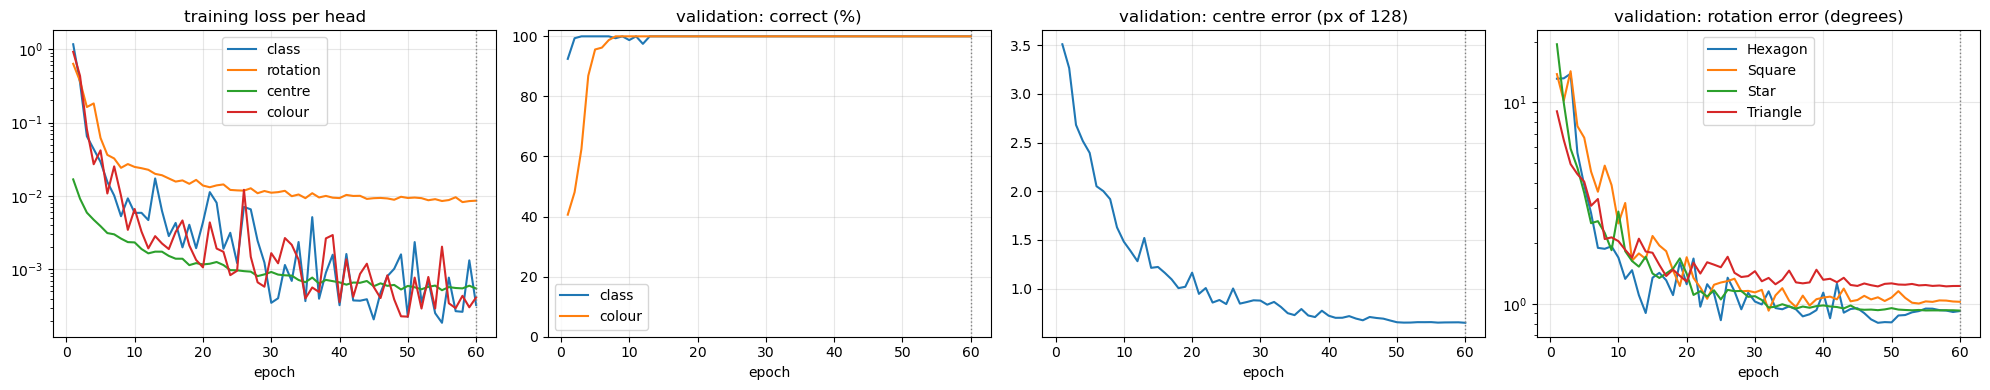

epoch 60/60 | class 100% | colour 100% | centre 0.65 px | rotation 1.03° | best epoch so far: 60


In [4]:
train_loader, val_loader = make_loaders(crops)
print(len(train_loader.dataset.crops), "crops training,", len(val_loader.dataset.crops), "validation")


def plot_history(history):
    h = pd.DataFrame(history)
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 4, figsize=(20, 4))
    for col, lab in [("class_loss", "class"), ("rotation_loss", "rotation"), ("centre_loss", "centre"), ("colour_loss", "colour")]:
        ax[0].plot(h["epoch"], h[col], label=lab)
    ax[0].set_yscale("log"); ax[0].set_title("training loss per head"); ax[0].legend()
    ax[1].plot(h["epoch"], h["val_class"] * 100, label="class")
    ax[1].plot(h["epoch"], h["val_colour"] * 100, label="colour")
    ax[1].set_ylim(0, 102); ax[1].set_title("validation: correct (%)"); ax[1].legend()
    ax[2].plot(h["epoch"], h["val_centre_px"]); ax[2].set_title("validation: centre error (px of 128)")
    for s in SYMMETRY_DEG:
        ax[3].plot(h["epoch"], h[f"val_rot_{s}"], label=s)
    ax[3].set_yscale("log"); ax[3].set_title("validation: rotation error (degrees)"); ax[3].legend()
    best = h.loc[h["score"].idxmin(), "epoch"]
    for a in ax:
        a.axvline(best, color="grey", ls=":", lw=1); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    last = h.iloc[-1]
    print(f"epoch {int(last.epoch)}/{EPOCHS} | class {last.val_class:.0%} | colour {last.val_colour:.0%} | "
          f"centre {last.val_centre_px:.2f} px | rotation {last.val_rotation:.2f}° | best epoch so far: {int(best)}")


model, history = T.train(train_loader, val_loader, epochs=EPOCHS, on_epoch=plot_history)

## Learning rate

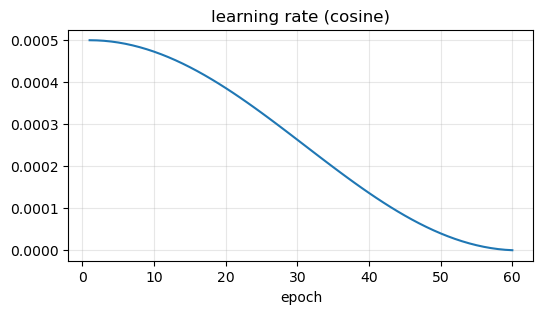

In [5]:
h = pd.DataFrame(history)
plt.figure(figsize=(6, 3)); plt.plot(h["epoch"], h["lr"])
plt.title("learning rate (cosine)"); plt.xlabel("epoch"); plt.grid(alpha=0.3); plt.show()

## Slutkontroll
Bästa epoch:en, på validation-crops med sina **riktiga** färger (inga bytta kanaler).

In [6]:
T.final_check(model, val_loader.dataset.crops)

class:    40/40 correct
colour:   40/40 correct
centre:   1.2 px mean error (crop pixels)
rotation: Hexagon   0.90° mean error
rotation: Square    1.03° mean error
rotation: Star      0.61° mean error
rotation: Triangle  1.34° mean error


## Colour på riktiga bitar

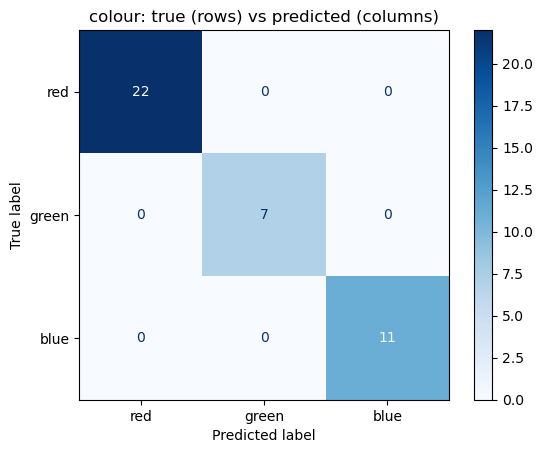

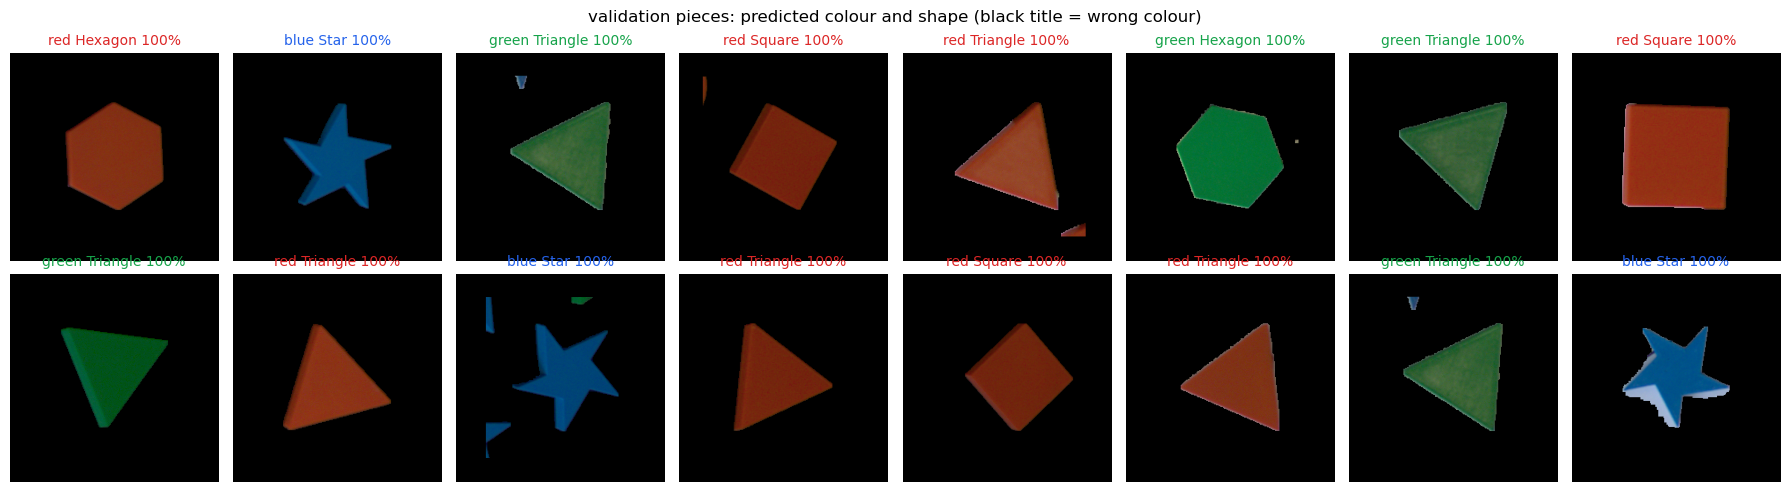

In [7]:
import cv2
from sklearn.metrics import ConfusionMatrixDisplay
from neural_net.preprocess import square_canvas, to_input

model.eval()
truth, pred, conf, imgs = [], [], [], []
with torch.no_grad():
    for _, row in val_loader.dataset.crops.iterrows():
        canvas, _ = square_canvas(cv2.imread(row["path"]))
        out = model(torch.from_numpy(to_input(canvas))[None].to(T.DEVICE))
        p = torch.softmax(out[3][0], 0)
        truth.append(row["colour"]); pred.append(COLOURS[p.argmax().item()]); conf.append(p.max().item())
        imgs.append((cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB), CLASSES[out[0].argmax().item()]))

ConfusionMatrixDisplay.from_predictions(truth, pred, labels=COLOURS, cmap="Blues")
plt.title("colour: true (rows) vs predicted (columns)"); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, (img, shape), c, t, p in zip(axes.flat, imgs, conf, truth, pred):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{p} {shape} {c:.0%}", color=PLOT_COLOURS[p] if p == t else "black",
                 fontweight="bold" if p != t else "normal", fontsize=10)
plt.suptitle("validation pieces: predicted colour and shape (black title = wrong colour)"); plt.tight_layout(); plt.show()

## Export till ONNX (det roboten använder)

In [8]:
T.export_onnx(model)

import onnxruntime as ort
from neural_net.config import ONNX_PATH
x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    ref = model.cpu()(x)
onnx_out = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"]).run(None, {"input": x.numpy()})
for name, a, b in zip(["class", "rotation", "centre", "colour"], ref, onnx_out):
    print(f"{name:<9} {tuple(b.shape)}  max difference vs PyTorch {np.abs(a.numpy() - b).max():.1e}")

saved /home/Nilse/Desktop/PhysicalAIBinPicking/chudbot/ReWorks/neural_net/models/crpnet.onnx
class     (2, 5)  max difference vs PyTorch 1.9e-06
rotation  (2, 5, 2)  max difference vs PyTorch 4.6e-07
centre    (2, 2)  max difference vs PyTorch 8.9e-08
colour    (2, 3)  max difference vs PyTorch 2.2e-06
